In [1]:
import Defaults
from qiskit.circuit.library import UnitaryGate, QFTGate
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import QFTGate
from math import log, floor, gcd, ceil, log2
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from time import time
from Gates import AdditionalGates as QC

t=[]

DEBUG = True
plt.rcParams["figure.figsize"] = (20,5)
style = "latex"

from IPython.core.magic import register_cell_magic
from IPython import get_ipython
from IPython.display import display

@register_cell_magic
def skip(line, cell):
    return

@register_cell_magic
def skip_if(line, cell):
    if eval(line):
        return
    get_ipython().run_cell(cell)

In [2]:
def perm_matrix_multmod(a, N, n = None):
    n = n or ceil(log2(N))
    dim = 2 ** n
    U = np.identity(dim, np.int32)
    for x in range(N):
        U[x, x] = 0
        U[(a * x % N), x] = 1
    G = UnitaryGate(U)
    G.name = "\\ket{x}\\rightarrow\\ket{x\\cdot" + str(a) + " mod " + str(N) +"}"
    return G

In [3]:
a=2
N=15
if gcd(a, N) > 1:
    print(f"Error: gcd({a},{N}) > 1")
    quit()

k=2*ceil(log2(N))
b_list = [pow(a,2**val,N) for val in range(k)]

work_bits = k//2
phase_bits = k

Phase_Register = QuantumRegister(phase_bits,"P")
Work_Register = QuantumRegister(work_bits,"W")
meas = ClassicalRegister(phase_bits,"meas")
qc = QC(Phase_Register, Work_Register, meas)
qc.h(Phase_Register)
qc.x(Work_Register[0])

gates ={}

for index in range(len(b_list)):
    b = b_list[index]
    if not (str(b) in gates.keys()):
        gates[str(b)] = perm_matrix_multmod(b,N,work_bits).control()
    if b > 1:
        qc.compose(gates[str(b)], qubits=[Phase_Register[index]] + list(Work_Register), inplace=True)

qc.compose(QFTGate(phase_bits).inverse(),Phase_Register,inplace=True)
qc.measure(Phase_Register, meas)

qc.count_ops()

OrderedDict([('h', 8),
             ('measure', 8),
             ('c-unitary', 2),
             ('x', 1),
             ('qft_dg', 1)])

In [4]:
sim = Defaults.Simulation()

print("Qubits:",sim.backend.num_qubits)

Qubits: 31


In [5]:
t.append(time())
decomp = [qc]
t.append(time())
gates = decomp[-1].count_ops()
print(f"decomposition 0: {str(float(0))[:6]}s, gate types: {str(len(gates)).zfill(3)}, number of gates: {str(sum(gates.values())).zfill(7)}, Gates: {list(gates.keys())}")
for i in range(0,10):
    t.append(time())
    decomp.append((decomp[-1] if len(decomp) > 0 else qc).decompose())
    t.append(time())
    new_gates = decomp[-1].count_ops()
    if new_gates == gates:
        break
    else:
        gates = new_gates
    print(f"decomposition {i+1}: {str(t[-1]-t[-2])[:6]}s, gate types: {str(len(gates)).zfill(3)}, number of gates: {str(sum(gates.values())).zfill(7)}, Gates: {list(gates.keys())}")
smallest = -1
for i, circ in enumerate(decomp):
    t.append(time())
    sim.update_isa_circuit(circ)
    t.append(time())
    gates = sim.isa_circuit.count_ops()
    if smallest == -1 or sum(gates.values()) < sum(decomp[smallest].count_ops().values()) :
        smallest = i
    print(f"decomposition {i}: {str(t[-1]-t[-2])[:6]}s, gate types: {str(len(gates)).zfill(3)}, number of gates: {str(sum(gates.values())).zfill(7)}, Gates: {list(gates.keys())}")
sim.update_isa_circuit(decomp[smallest])

decomposition 0: 0.0s, gate types: 005, number of gates: 0000020, Gates: ['h', 'measure', 'c-unitary', 'x', 'qft_dg']
decomposition 1: 0.0095s, gate types: 011, number of gates: 0000063, Gates: ['cp', 'u', 'h', 'measure', 'swap', 'circuit-170', 'circuit-179', 'circuit-305', 'circuit-461', 'circuit-470', 'circuit-617']
decomposition 2: 0.0111s, gate types: 018, number of gates: 0000250, Gates: ['cx', 'p', 'rz', 'u', 'h', 'measure', 'circuit-47', 'circuit-121', 'circuit-84', 'circuit-182', 'circuit-256', 'circuit-219', 'circuit-317', 'circuit-391', 'circuit-354', 'circuit-473', 'circuit-547', 'circuit-510']
decomposition 3: 0.0112s, gate types: 032, number of gates: 0000266, Gates: ['u', 'cx', 'p', 'measure', 'circuit-72', 'circuit-81', 'circuit-146', 'circuit-155', 'circuit-158', 'circuit-85_reverse', 'circuit-112', 'circuit-207', 'circuit-216', 'circuit-257', 'circuit-269', 'circuit-296', 'circuit-220_reverse', 'circuit-247', 'circuit-342', 'circuit-351', 'circuit-416', 'circuit-425', 

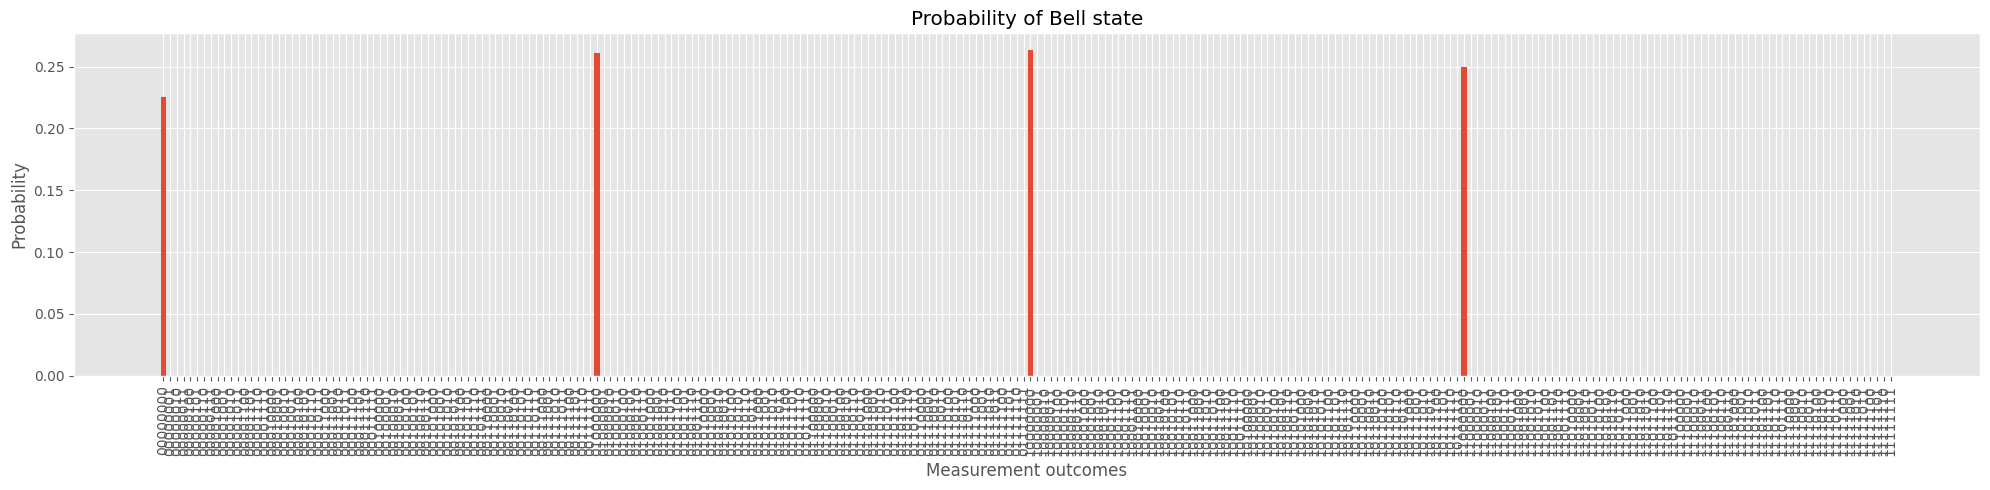

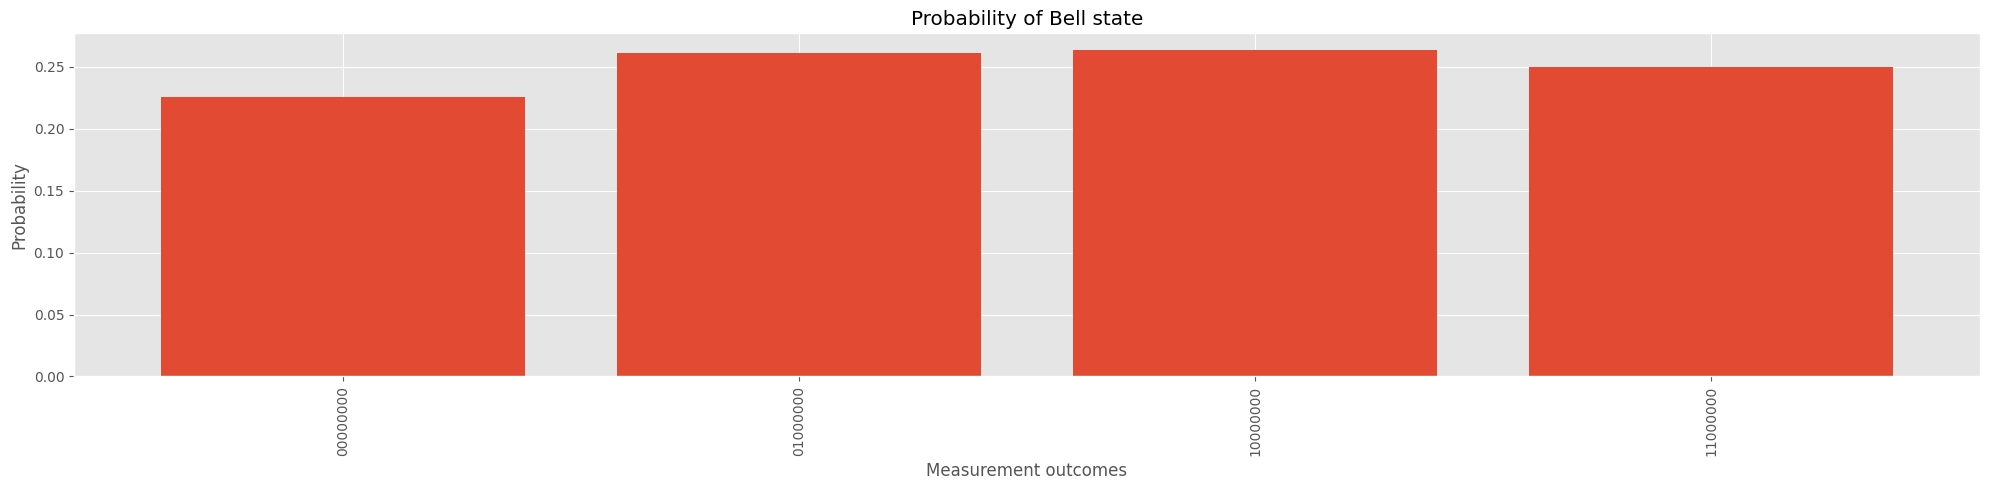

In [8]:
job_name = f"Shor({a},{N}) perm sample"
result = sim.get_result(job_name)
if result:
    if result == True:
        print("Waiting on result")
    else:
        sim_probs = Defaults.get_probs(result,Defaults.generate_dict(phase_bits), percentage=True)
        graph_probs = Defaults.tidy_probs(sim_probs,0.01)
        Defaults.create_bar(sim_probs.keys(), sim_probs.values(), xlabel="Measurement outcomes", ylabel="Probability", title="Probability of Bell state").show()
        Defaults.create_bar(graph_probs.keys(), graph_probs.values(), xlabel="Measurement outcomes", ylabel="Probability", title="Probability of Bell state").show()
else:
    if result == False:
        print("Job was cancelled or errored")
    else:
        #sim.update_isa_circuit(qc)
        sim.save_job(sim.sampler.run([sim.isa_circuit],shots=1024),job_name)
        print("Job Started")

In [9]:
%%skip_if result in [None, False, True]
counts = result[0].data.meas.get_counts()
counts_keep = {}
threshold = np.max(list(counts.values())) / 5

for key, value in counts.items():
    if value > threshold:
        counts_keep[key] = value

found = False
attempt = 0
while not found:
    bitstring = list(counts_keep.keys())[attempt]
    attempt += 1
    decimal = int(bitstring, 2)
    if decimal != 0:
        phase = decimal / (2**phase_bits)
        frac = Fraction(phase).limit_denominator(N)
        r = frac.denominator
        if r % 2 == 0:
            x = pow(a, r // 2, N) - 1
            d = gcd(x, N)
            print(r,x,d)
            if d > 1:
                found = True
                print(f"*** Non-trivial factor found: {x}, GCD({x},{N}): {gcd(x,N)} ***")

4 3 3
*** Non-trivial factor found: 3, GCD(3,15): 3 ***
